In [3]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working in:", os.getcwd())

Working in: /Users/jamesfamodimu/Documents/energy-efficiency


In [4]:
from pathlib import Path
from itertools import combinations
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold,
StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.mixture import GaussianMixture
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
roc_auc_score, brier_score_loss, accuracy_score, confusion_matrix)
import joblib
import json



SEED = 42


rng = np.random.default_rng(SEED)
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
for d in ["figures", "outputs", "model"]:
    Path(d).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
"axes.spines.top": False, "axes.spines.right": False})
print("Setup is complete")

Setup is complete


Loading the data

In [5]:
import pandas as pd
print(pd.__version__)

3.0.3


In [6]:
from src.data import load_data, SEED, TARGETS, NUM, CAT, THRESH
df = load_data()
print(df.shape)
df.tail()

(768, 10)


,compactness,surface_area,wall_area,roof_area,height,orientation,glazing_area,glazing_dist,heating_load,cooling_load
763,0.64,784.0,343.0,220.5,3.5,5,0.4,5,17.88,21.40
764,0.62,808.5,367.5,220.5,3.5,2,0.4,5,16.54,16.88
765,0.62,808.5,367.5,220.5,3.5,3,0.4,5,16.44,17.11
766,0.62,808.5,367.5,220.5,3.5,4,0.4,5,16.48,16.61
767,0.62,808.5,367.5,220.5,3.5,5,0.4,5,16.64,16.03


Checking for duplicate rows and missing values

In [7]:
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isna().sum().sum())

pd.DataFrame({"dtype": df.dtypes,
             "unique": df.nunique(),
             "min": df.min(),
             "max": df.max()
             })

Duplicate Rows: 0
Missing Values: 0


,dtype,unique,min,max
compactness,float64,12,0.62,0.98
surface_area,float64,12,514.50,808.50
wall_area,float64,7,245.00,416.50
roof_area,float64,4,110.25,220.50
height,float64,2,3.50,7.00
orientation,int64,4,2.00,5.00
glazing_area,float64,4,0.00,0.40
glazing_dist,int64,6,0.00,5.00
heating_load,float64,586,6.01,43.10
cooling_load,float64,636,10.90,48.03


Checking relationships between features

In [9]:
print(f"surface = wall + 2*roof: {np.allclose(df.surface_area, df.wall_area + 2 * df.roof_area)}")

print(f"glazing 0 -> dist 0: {(df.loc[df.glazing_area == 0, 'glazing_dist'] == 0).all()}")

print(f"Shapes x orientations x glazing setups: {df.compactness.nunique()} x {df.orientation.nunique()} x {len(df) // 48} = {len(df)}")

df.groupby("compactness")[["surface_area", "wall_area", "roof_area", "height"]].first()


surface = wall + 2*roof: True
glazing 0 -> dist 0: True
Shapes x orientations x glazing setups: 12 x 4 x 16 = 768


,surface_area,wall_area,roof_area,height
compactness,,,,
0.62,808.5,367.5,220.50,3.5
0.64,784.0,343.0,220.50,3.5
0.66,759.5,318.5,220.50,3.5
0.69,735.0,294.0,220.50,3.5
0.71,710.5,269.5,220.50,3.5
0.74,686.0,245.0,220.50,3.5
0.76,661.5,416.5,122.50,7.0
0.79,637.0,343.0,147.00,7.0
0.82,612.5,318.5,147.00,7.0


In [18]:
descriptive_stats = df.describe().transpose()

descriptive_stats["skew"] = df.skew(numeric_only=True)
descriptive_stats["kurtosis"] = df.kurt(numeric_only=True)

descriptive_stats.round(3).to_csv("outputs/descriptive_stats.csv", index=True)
target_stats = descriptive_stats.loc[TARGETS].round(3)

print(target_stats)


              count    mean     std    min     25%    50%     75%    max   skew  kurtosis
heating_load  768.0  22.307  10.090   6.01  12.992  18.95  31.668  43.10  0.360    -1.246
cooling_load  768.0  24.588   9.513  10.90  15.620  22.08  33.132  48.03  0.396    -1.147


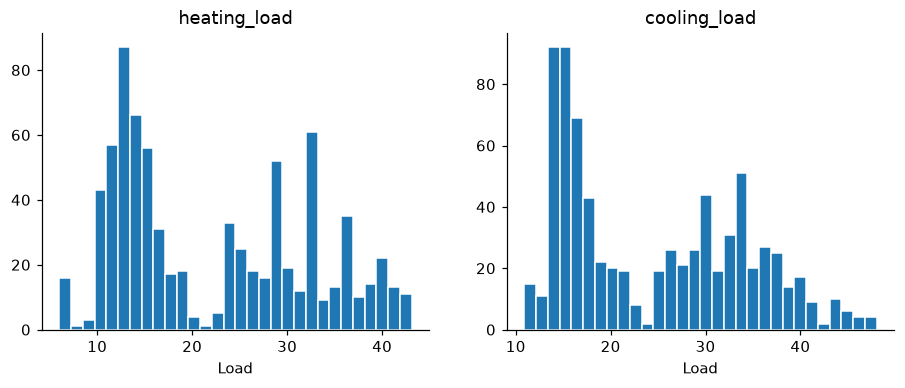

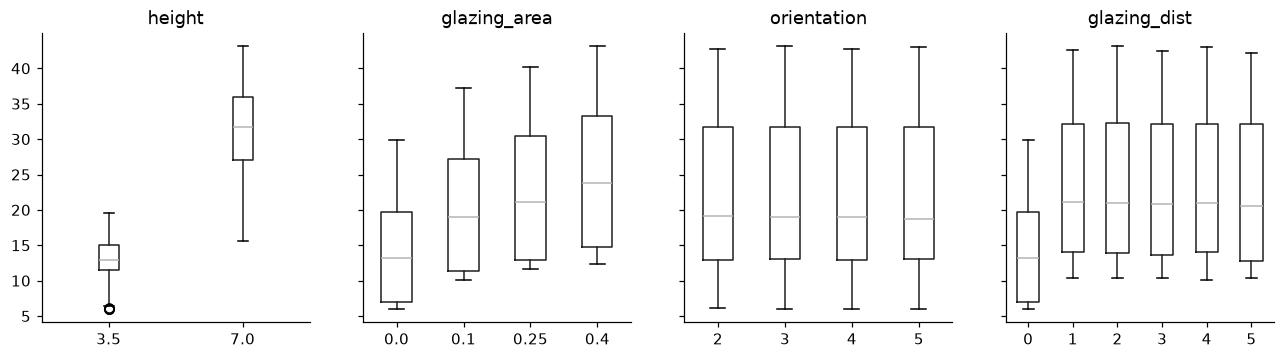

In [25]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 3.5))
for ax, target in zip(axes, TARGETS):
    ax.hist(df[target], bins = 30, edgecolor = "white")
    ax.set_title(target)
    ax.set_xlabel("Load")
fig.savefig("figures/01_targets.png")
plt.show()

factors = ["height", "glazing_area", "orientation", "glazing_dist"]
fig, axes = plt.subplots(nrows = 1, ncols = 4, figsize = (14, 3.5), sharey = True)
for ax, factor in zip(axes, factors):
    df.boxplot(column = "heating_load", by = factor, ax = ax, grid = False)
    ax.set_title(factor)
    ax.set_xlabel("")
plt.suptitle("")
fig.savefig("figures/02_boxplots.png")
plt.show()


In [31]:
correlation_matrix = df.corr(method="spearman")
print(correlation_matrix[TARGETS].drop(index=TARGETS).round(2))

def calculate_vif(data_frame):
    data_with_constant = sm.add_constant(data_frame)
    vif_values = [
        variance_inflation_factor(data_with_constant.values, index) 
        for index in range(1, data_with_constant.shape[1])
    ]
    return pd.Series(vif_values, index=data_with_constant.columns[1:]).round(1)

print(calculate_vif(df[NUM]))


              heating_load  cooling_load
compactness           0.62          0.65
surface_area         -0.62         -0.65
wall_area             0.47          0.42
roof_area            -0.80         -0.80
height                0.86          0.86
orientation          -0.00          0.02
glazing_area          0.32          0.29
glazing_dist          0.07          0.05
compactness     105.5
wall_area        27.7
roof_area       211.9
height           31.2
glazing_area      1.0
dtype: float64
